# Sesión 1/6 · IA, Machine Learning y Deep Learning aplicados a ciberseguridad
**Máster en Ciberseguridad · Laboratorio guiado desde cero**

**Problema:** tenemos registros de conexiones de red y queremos decidir cuáles parecen normales y cuáles corresponden a ataques. Primero escribiremos una regla manual y después dejaremos que un algoritmo aprenda reglas a partir de ejemplos.

**Al terminar podrás explicar** qué son IA, ML y DL; qué es un *dataset*; cómo se carga, analiza y etiqueta el tráfico; cómo se entrena y evalúa un clasificador; por qué la exactitud puede engañar; qué significa el sobreajuste y cómo afecta la deriva de los datos.

| Recorrido | Qué aprenderemos y para qué |
|---|---|
| Preparación | Instalar bibliotecas y descargar los archivos del laboratorio. |
| A. Datos | Crear `utils.py` y transformar conexiones en una tabla con etiquetas. |
| B. Exploración | Comprender clases, cantidades, escalas y distribuciones antes de aprender. |
| C. Regla frente a árbol | Comparar una decisión escrita a mano con decisiones aprendidas. |
| D. Generalización | Separar entrenamiento y prueba y estudiar el sobreajuste. |
| E. Tasa base | Comprender falsas alarmas y la precisión real de un detector. |
| F. Caso práctico | Diseñar una aplicación de ML con sentido operativo. |
| G. Umbrales | Aprender una regla óptima sin usar una biblioteca de ML. |
| Ampliación | Comparar reglas y regresión logística; medir la deriva del atacante. |

> **Cómo trabajar:** lee el Markdown **anterior** a cada celda, ejecútala con `Mayús + Intro` y contrasta el resultado con la interpretación inmediatamente posterior. Las respuestas a los ejercicios están desarrolladas para que puedas comprobar tu razonamiento; no son tareas pendientes. El cuaderno funciona como un recorrido, no como una colección de fragmentos independientes.

## Antes de empezar · IA, ML, DL y vocabulario imprescindible

**Inteligencia artificial (IA)** es el campo amplio que busca crear sistemas capaces de realizar tareas asociadas con la inteligencia (decidir, reconocer patrones, interpretar lenguaje…). No toda IA aprende: un filtro que aplica reglas escritas por personas es un ejemplo de sistema basado en reglas que puede formar parte de una solución de IA.

**Machine Learning (ML, aprendizaje automático)** es una forma de construir estos sistemas: en lugar de programar todas las reglas, el algoritmo las **ajusta usando ejemplos**. Por ejemplo, aprende qué combinaciones de señales de una conexión suelen aparecer en ataques.

**Deep Learning (DL, aprendizaje profundo)** es una familia de ML que utiliza redes neuronales de múltiples capas. Puede aprender representaciones complejas, por ejemplo a partir de secuencias de eventos o contenido de correos. No es automáticamente mejor que un árbol para una tabla pequeña de variables.

**Ejemplo comparado:** para detectar un correo sospechoso, una regla puede decir «si contiene *urgente*, alerta»; un modelo ML puede combinar *urgente*, dominio del remitente y adjuntos; un modelo DL puede aprender patrones a partir del texto y otras señales. **IA ⊃ ML ⊃ DL**: cada categoría contiene a la siguiente.

**Cinco términos para leer el cuaderno:**

| Término | Qué significa | Ejemplo de tráfico |
|---|---|---|
| **Observación / fila** | Un caso registrado. | Una conexión. |
| **Característica / *feature* / columna de entrada** | Un dato medible con el que decidir. | `duration`: duración en segundos. |
| **Etiqueta / objetivo / *target*** | La respuesta correcta conocida en el conjunto de ejemplo. | `is_attack`: `0` normal, `1` ataque. |
| **Entrenar / ajustar / `fit`** | Construir reglas internas usando entradas y etiquetas. | Aprender cortes sobre tasas de error y cantidades. |
| **Predecir / `predict`** | Aplicar el modelo ya ajustado a entradas para obtener una clasificación. | Predecir `1` para una nueva conexión. |

En este cuaderno practicamos **aprendizaje supervisado**: conocemos la etiqueta de los ejemplos con los que entrenamos. La tarea es **clasificación binaria**, porque únicamente distinguimos dos clases: normal (`0`) y ataque (`1`). El modelo no «entiende» el ataque: aprende relaciones presentes en los datos etiquetados.

## Preparación · Qué se instala y de dónde salen los datos

Un notebook es un documento formado por **celdas de texto** y **celdas de Python**. Las variables permanecen en memoria mientras el *kernel* (el proceso que ejecuta Python) está activo. Por eso debemos ejecutar de arriba abajo: si una celda necesita `df`, antes ha de ejecutarse la celda que creó `df`.

- **Google Colab:** sube este `.ipynb`; el almacenamiento temporal se pierde al desconectar y la preparación debe repetirse.
- **VS Code / Jupyter / Codespaces:** abre el notebook, selecciona un kernel de Python y ejecuta la preparación desde la carpeta del proyecto.
- **Primera ejecución:** necesita conexión a Internet para instalar bibliotecas ausentes y descargar `KDDTrain+.txt` y `KDDTest+.txt`. Después reutiliza los archivos locales de `data/`.

**Bibliotecas:** `numpy` maneja arrays numéricos; `pandas` maneja tablas (*DataFrames*); `scikit-learn` aporta modelos y métricas; `matplotlib` dibuja gráficos. También se conservan `seaborn`, `imbalanced-learn` y `joblib` como dependencias previstas en el material original, aunque esta sesión no utiliza sus funciones.

**Dataset NSL-KDD:** archivo público para practicar detección de intrusiones. Cada fila describe una conexión mediante **41 características** de tráfico, más su `label` (nombre del tipo de tráfico) y su `difficulty` (campo de dificultad incluido en el dataset). **No representa la tasa real de ataques de una red actual**, ni debe tratarse como fuente de rendimiento operativo de un detector moderno. Aquí es un banco de pruebas pedagógico.

In [1]:
# PREPARACIÓN. Esta celda solo instala dependencias ausentes y descarga archivos que no existan.
import importlib.util
import os
import subprocess
import sys
import urllib.request

from IPython.display import display  # Presenta DataFrames con formato de tabla en Jupyter.

print("=" * 65)
print("PREPARACIÓN · Entorno de ejecución")
print("=" * 65)
en_colab = "google.colab" in sys.modules
print(f"Entorno: {'Google Colab' if en_colab else 'Jupyter / VS Code / Codespaces'}")
print(f"Versión de Python: {sys.version.split()[0]}")

# Clave: nombre con el que se importa; valor: nombre del paquete para pip.
paquetes = {
    "numpy": "numpy",
    "pandas": "pandas",
    "sklearn": "scikit-learn",
    "matplotlib": "matplotlib",
    "seaborn": "seaborn",
    "imblearn": "imbalanced-learn",
    "joblib": "joblib",
}
paquetes_ausentes = [
    nombre_pip
    for nombre_modulo, nombre_pip in paquetes.items()
    if importlib.util.find_spec(nombre_modulo) is None
]

if paquetes_ausentes:
    print(f"\nInstalando bibliotecas ausentes: {', '.join(paquetes_ausentes)}")
    # sys.executable garantiza que pip corresponde al mismo Python que el notebook.
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", "-q", *paquetes_ausentes]
    )
else:
    print("\nBibliotecas: todas las necesarias están instaladas.")

# Archivos oficiales que reutilizaremos: entrenamiento y prueba son distintos.
url_base = "https://raw.githubusercontent.com/defcom17/NSL_KDD/master/"
os.makedirs("data", exist_ok=True)  # exist_ok evita errores al repetir la ejecución.

print("\n" + "-" * 65)
print("DATOS · Archivos locales de NSL-KDD")
print("-" * 65)
for nombre_archivo in ["KDDTrain+.txt", "KDDTest+.txt"]:
    ruta_local = os.path.join("data", nombre_archivo)
    if not os.path.exists(ruta_local):
        # %2B es la representación del carácter '+' dentro de la URL.
        print(f"Descargando {nombre_archivo}...")
        urllib.request.urlretrieve(url_base + nombre_archivo.replace("+", "%2B"), ruta_local)
        procedencia = "descargado ahora"
    else:
        procedencia = "ya estaba guardado"
    tamano_mb = os.path.getsize(ruta_local) / 1e6  # 1 MB decimal = 1 000 000 bytes.
    print(f"{nombre_archivo}: {tamano_mb:.1f} MB ({procedencia})")

import numpy
import pandas
import sklearn

print("\n" + "-" * 65)
print("BIBLIOTECAS · Versiones utilizadas")
print("-" * 65)
print(f"NumPy:        {numpy.__version__}")
print(f"pandas:       {pandas.__version__}")
print(f"scikit-learn: {sklearn.__version__}")
print("\nPreparación terminada. Los archivos se encuentran en ./data/")

PREPARACIÓN · Entorno de ejecución
Entorno: Jupyter / VS Code / Codespaces
Versión de Python: 3.12.3

Bibliotecas: todas las necesarias están instaladas.

-----------------------------------------------------------------
DATOS · Archivos locales de NSL-KDD
-----------------------------------------------------------------
KDDTrain+.txt: 19.1 MB (ya estaba guardado)
KDDTest+.txt: 3.4 MB (ya estaba guardado)

-----------------------------------------------------------------
BIBLIOTECAS · Versiones utilizadas
-----------------------------------------------------------------
NumPy:        2.5.5
pandas:       3.1.1
scikit-learn: 1.9.1

Preparación terminada. Los archivos se encuentran en ./data/


## Parte A · Del archivo a una tabla preparada para clasificación

**Objetivo:** leer conexiones de NSL-KDD y añadir una respuesta binaria («normal» o «ataque») que puedan utilizar los clasificadores. Los archivos `.txt` contienen **valores separados por comas sin fila de encabezados**: debemos indicar los nombres de las columnas al leerlos.

**`utils.py` es un módulo de Python:** un archivo de funciones reutilizables. La próxima celda usa `%%writefile utils.py`, una instrucción de Jupyter que **escribe el código de la celda en un archivo**; no es una función normal de Python. Se crea en la carpeta desde la que se ejecuta el notebook. La función `load_nsl_kdd` leerá el archivo de entrenamiento (`split="train"`) o el de prueba (`split="test"`).

**Qué significa crear `is_attack`:** si `label` vale `normal`, asignamos `0`; para cualquier otro nombre (por ejemplo `neptune`), asignamos `1`. La condición `(label != "normal")` produce valores verdadero/falso y `.astype(int)` los convierte en `1`/`0`. **No borramos `label` ni `difficulty`**: los conservamos para explorarlos, pero no deben filtrarse como entradas del clasificador porque contienen información de la respuesta o metadatos.

In [2]:
%%writefile utils.py
"""Carga del dataset NSL-KDD para los laboratorios del curso."""

import os
import urllib.request

import pandas as pd

NSL_URL = "https://raw.githubusercontent.com/defcom17/NSL_KDD/master/"

# El orden importa: read_csv asignará estos nombres a las 43 columnas del fichero.
# 41 características de una conexión, seguidas de su etiqueta y dificultad.
NSL_COLS = [
    # Datos básicos de conexión.
    "duration", "protocol_type", "service", "flag", "src_bytes", "dst_bytes",
    "land", "wrong_fragment", "urgent",
    # Señales sobre el contenido y los accesos observados.
    "hot", "num_failed_logins", "logged_in", "num_compromised", "root_shell",
    "su_attempted", "num_root", "num_file_creations", "num_shells",
    "num_access_files", "num_outbound_cmds", "is_host_login", "is_guest_login",
    # Estadísticas sobre conexiones recientes.
    "count", "srv_count", "serror_rate", "srv_serror_rate", "rerror_rate",
    "srv_rerror_rate", "same_srv_rate", "diff_srv_rate", "srv_diff_host_rate",
    # Estadísticas sobre conexiones hacia equipos de destino.
    "dst_host_count", "dst_host_srv_count", "dst_host_same_srv_rate",
    "dst_host_diff_srv_rate", "dst_host_same_src_port_rate",
    "dst_host_srv_diff_host_rate", "dst_host_serror_rate",
    "dst_host_srv_serror_rate", "dst_host_rerror_rate", "dst_host_srv_rerror_rate",
    # Campos de referencia: nunca se usan como variables predictoras aquí.
    "label", "difficulty",
]


def load_nsl_kdd(split="train", base="data"):
    """Devuelve un DataFrame del conjunto de entrenamiento o de prueba.

    split: 'train' para KDDTrain+.txt; 'test' para KDDTest+.txt.
    base: carpeta donde se buscan o descargan los archivos.
    Añade 'is_attack': 0 si la etiqueta es normal y 1 en otro caso.
    """
    # Elegimos uno de los dos ficheros: no mezclamos entrenamiento y prueba.
    nombre_archivo = "KDDTrain+.txt" if split == "train" else "KDDTest+.txt"
    ruta_archivo = os.path.join(base, nombre_archivo)

    if not os.path.exists(ruta_archivo):
        # Descarga de respaldo si no se ejecutó la celda de preparación.
        os.makedirs(base, exist_ok=True)
        url_archivo = NSL_URL + nombre_archivo.replace("+", "%2B")
        urllib.request.urlretrieve(url_archivo, ruta_archivo)

    # header=None: el fichero no trae cabecera; names=...: asigna nombres.
    # Cada línea pasa a ser una fila, cada valor separado por comas una columna.
    datos = pd.read_csv(ruta_archivo, header=None, names=NSL_COLS)

    # Comparación elemento a elemento: 'normal' -> False -> 0; ataques -> True -> 1.
    datos["is_attack"] = (datos["label"] != "normal").astype(int)
    return datos

Overwriting utils.py


### A.1 · Cargar el entrenamiento e inspeccionar filas reales

`DataFrame` significa «tabla»: tiene **filas**, **columnas** y sus nombres. Guardaremos el entrenamiento en `df`. La propiedad `df.shape` devuelve `(número_de_filas, número_de_columnas)`; `df.head()` obtiene las cinco primeras filas; para facilitar la lectura mostramos **solo nueve columnas ilustrativas**, aunque `df` conserva las 44.

**Referencia esperada del NSL-KDD original:** 125.973 filas × **44 columnas** = 41 características + `label` + `difficulty` + `is_attack`. El archivo solo trae **43** columnas; la 44.ª se crea en `load_nsl_kdd`.

In [3]:
import importlib
import utils

# Si editas y vuelves a ejecutar %%writefile, reload evita utilizar una versión
# antigua del módulo que aún estuviera cargada en memoria.
importlib.reload(utils)
load_nsl_kdd = utils.load_nsl_kdd

# 'train' lee KDDTrain+.txt; 'df' será nuestra tabla de entrenamiento.
df = load_nsl_kdd("train")

print("=" * 65)
print("PARTE A · Conexiones de entrenamiento NSL-KDD")
print("=" * 65)
print(f"Número de conexiones (filas): {df.shape[0]:,}".replace(",", "."))
print(f"Número de columnas (incluida la nueva etiqueta): {df.shape[1]}")
print("Nueva variable objetivo: is_attack (0 = normal, 1 = ataque)")
columnas_vista_previa = [
    "duration", "protocol_type", "service", "src_bytes", "dst_bytes",
    "serror_rate", "label", "difficulty", "is_attack",
]
print("\nPrimeras cinco conexiones · 9 columnas representativas de las 44:")
print("Las columnas omitidas en la vista siguen existiendo en 'df'.")
display(df[columnas_vista_previa].head())

PARTE A · Conexiones de entrenamiento NSL-KDD
Número de conexiones (filas): 125.973
Número de columnas (incluida la nueva etiqueta): 44
Nueva variable objetivo: is_attack (0 = normal, 1 = ataque)

Primeras cinco conexiones · 9 columnas representativas de las 44:
Las columnas omitidas en la vista siguen existiendo en 'df'.


,duration,protocol_type,service,src_bytes,dst_bytes,serror_rate,label,difficulty,is_attack
0,0,tcp,ftp_data,491,0,0.0,normal,20,0
1,0,udp,other,146,0,0.0,normal,15,0
2,0,tcp,private,0,0,1.0,neptune,19,1
3,0,tcp,http,232,8153,0.2,normal,21,0
4,0,tcp,http,199,420,0.0,normal,21,0


**Cómo interpretar la salida:** cada fila es una conexión, `duration` es su duración, `protocol_type` indica el protocolo y `label` da el nombre real de su clase. `is_attack=1` solo significa «no es `normal`»: no identifica el ataque concreto. Ver cinco filas sirve para comprobar la estructura, **no** para conocer la distribución del dataset entero.

## Parte B · Explorar antes de construir un detector

**Objetivo:** averiguar qué estamos intentando clasificar, qué clases predominan y cuáles son las escalas de los datos. Sin esta comprobación es fácil confundir un modelo aparentemente bueno con uno que simplemente aprovecha un desequilibrio de clases.

**Frecuencia absoluta** = número de filas de una clase; **frecuencia relativa** = número de filas de la clase dividido entre el total. Ejemplo: 20 ataques en 100 conexiones son 20 ataques y una proporción `20/100 = 0,20 = 20 %`. `value_counts()` cuenta; con `normalize=True` divide entre el total.

`label` contiene **nombres concretos** de comportamientos (por ejemplo `neptune`); `is_attack` los agrupa en dos clases. En NSL-KDD se estudian familias como **DoS** (denegación de servicio), **Probe** (exploración), **R2L** (acceso remoto a cuentas locales) y **U2R** (elevación de privilegios). El código siguiente cuenta etiquetas concretas, **no** calcula un desglose completo por familia.

In [4]:
import pandas as pd

# Tabla binaria: número y proporción de conexiones normales y de ataque.
conteo_clases = df["is_attack"].value_counts().reindex([0, 1], fill_value=0)
proporcion_clases = df["is_attack"].value_counts(normalize=True).reindex([0, 1], fill_value=0)
resumen_clases = pd.DataFrame({
    "Clase": ["Normal (0)", "Ataque (1)"],
    "Conexiones": conteo_clases.to_numpy(),
    "Porcentaje del total (%)": (proporcion_clases.to_numpy() * 100).round(2),
})

print("=" * 68)
print("PARTE B · 1. Distribución de clases (todas las conexiones)")
print("=" * 68)
display(resumen_clases)

# 'label' distingue ataques concretos. Mostramos las diez etiquetas más comunes.
print("\n" + "-" * 68)
print("2. Diez etiquetas más frecuentes (tipo concreto de tráfico)")
print("-" * 68)
frecuencias_etiquetas = df["label"].value_counts().head(10)
display(frecuencias_etiquetas.rename_axis("Etiqueta de tráfico").to_frame("Conexiones"))

# protocol_type es una variable categórica, no un número.
print("\n" + "-" * 68)
print("3. Conexiones por protocolo")
print("-" * 68)
display(df["protocol_type"].value_counts().rename_axis("Protocolo").to_frame("Conexiones"))

PARTE B · 1. Distribución de clases (todas las conexiones)


,Clase,Conexiones,Porcentaje del total (%)
0,Normal (0),67343,53.46
1,Ataque (1),58630,46.54



--------------------------------------------------------------------
2. Diez etiquetas más frecuentes (tipo concreto de tráfico)
--------------------------------------------------------------------


,Conexiones
Etiqueta de tráfico,
normal,67343
neptune,41214
satan,3633
ipsweep,3599
portsweep,2931
smurf,2646
nmap,1493
back,956
teardrop,892



--------------------------------------------------------------------
3. Conexiones por protocolo
--------------------------------------------------------------------


,Conexiones
Protocolo,
tcp,102689
udp,14993
icmp,8291


### B.1 · Interpretar la distribución y responder el ejercicio

**Pregunta 1. ¿Qué proporción del dataset es ataque? ¿Sirve como tasa base de una red real?** En el conjunto oficial `KDDTrain+` hay **58.630 ataques de 125.973 conexiones: aproximadamente 46,54 %** (y 67.343 conexiones normales, 53,46 %). La **tasa base** es la proporción previa de eventos verdaderamente maliciosos en el entorno que queremos monitorizar. **No podemos reutilizar el 46,54 % como tasa de una empresa real**: este conjunto es un benchmark preparado para experimentos y no una muestra representativa de una red de producción. Más adelante veremos por qué cambiar esa tasa altera radicalmente la precisión de las alertas.

**Pregunta 2. ¿Qué tipos de ataque hay y cuál domina?** Entre las etiquetas individuales aparece `neptune` (**41.214** conexiones en el archivo de entrenamiento), un ataque asociado a DoS mediante SYN flood: es **la etiqueta de ataque más frecuente**. También aparecen etiquetas como `satan`, `ipsweep`, `portsweep` o `smurf`. Esto no significa que `neptune` sea el ataque predominante en Internet: solo es el más repetido **en este dataset**. Si decimos «DoS domina», hablamos de una **familia**; si decimos «neptune domina», hablamos de una **etiqueta específica**. Son niveles distintos.

**Cuidado al interpretar:** una etiqueta muy repetida puede influir mucho en la puntuación de un clasificador; detectar bien `neptune` no implica detectar bien ataques raros. La pregunta «¿qué ataques tenemos?» requiere observar la columna `label`, no solo `is_attack`.

### B.2 · Escalas y estadística descriptiva desde cero

**Una escala** es el tamaño habitual de los valores de una variable. Una duración puede estar en segundos, el volumen transferido en bytes y una tasa en el intervalo `0–1`. Mezclarlas sin entenderlas puede confundir ciertos algoritmos, aunque los **árboles de decisión** que utilizaremos aquí **no necesitan estandarización** para comparar umbrales dentro de cada variable.

`describe()` calcula, para cada columna numérica: `count` (registros no nulos), `mean` (media), `std` (dispersión alrededor de la media), `min`, `25%` (primer cuartil), `50%` (**mediana**), `75%` (tercer cuartil) y `max`. La mediana es el punto por debajo o igual al cual queda al menos la mitad de los valores. Por ejemplo, en `[1, 1, 2, 100]`, la media es `26` y la mediana `1,5`; un valor extremo modifica mucho más la media.

En esta selección: `duration` se mide en segundos; `src_bytes` y `dst_bytes` en bytes; `count` es un recuento de conexiones recientes hacia el mismo destino; `serror_rate` es una **fracción** de errores SYN (por ejemplo `0,8 = 80 %`). **Un valor mayor no significa automáticamente mayor peligrosidad**.

In [5]:
# Conservamos exactamente las cinco columnas elegidas en el notebook original.
columnas_numericas = ["duration", "src_bytes", "dst_bytes", "count", "serror_rate"]

# .describe() resume cada variable; .T transpone: una variable por fila.
estadisticos = df[columnas_numericas].describe().T
estadisticos = estadisticos.rename(columns={
    "count": "N.º registros",
    "mean": "Media",
    "std": "Desv. típica",
    "min": "Mínimo",
    "25%": "25 %",
    "50%": "Mediana (50 %)",
    "75%": "75 %",
    "max": "Máximo",
})

print("=" * 75)
print("PARTE B · 4. Estadística descriptiva de cinco características")
print("=" * 75)
print("Unidades: duration = segundos; src_bytes/dst_bytes = bytes;")
print("          count = conexiones; serror_rate = proporción de 0 a 1.")
print("Los decimales de la tabla son solo formato de presentación.")
display(estadisticos.round(2))

PARTE B · 4. Estadística descriptiva de cinco características
Unidades: duration = segundos; src_bytes/dst_bytes = bytes;
          count = conexiones; serror_rate = proporción de 0 a 1.
Los decimales de la tabla son solo formato de presentación.


,N.º registros,Media,Desv. típica,Mínimo,25 %,Mediana (50 %),75 %,Máximo
duration,125973.0,287.14,2604.52,0.0,0.0,0.0,0.0,4.290800e+04
src_bytes,125973.0,45566.74,5870331.18,0.0,0.0,44.0,276.0,1.379964e+09
dst_bytes,125973.0,19779.11,4021269.15,0.0,0.0,0.0,516.0,1.309937e+09
count,125973.0,84.11,114.51,0.0,2.0,14.0,143.0,5.110000e+02
serror_rate,125973.0,0.28,0.45,0.0,0.0,0.0,1.0,1.000000e+00


**Pregunta 3. ¿Qué características tienen escalas muy distintas?** `src_bytes` y `dst_bytes` pueden alcanzar volúmenes elevados en **bytes**; `duration` está en **segundos** y `count` cuenta **conexiones**, mientras que `serror_rate` queda entre **0 y 1**. Para comprobarlo en la tabla, compara `Mediana (50 %)` y `Máximo` **dentro de cada fila**; un máximo enorme y una mediana pequeña indican una distribución muy asimétrica o valores extremos. No confundas «tener valores grandes» con «ser más importante para predecir».

**Qué sí podemos concluir:** las unidades y las magnitudes son diferentes. **Qué no podemos concluir solo con `describe()`:** qué variable detecta mejor los ataques. Para eso tenemos que **comparar valores según la etiqueta**.

### B.3 · Gráficos: ¿cambia una variable entre tráfico normal y ataques?

Un **histograma** cuenta cuántas filas caen dentro de intervalos (*bins*). Por ejemplo, con intervalos `0–0,05`, `0,05–0,10`, etc., la altura de cada barra representa el número de conexiones cuyo valor cae dentro del intervalo. Superponemos dos histogramas para cada variable: **normal (`0`)** y **ataque (`1`)**.

- **Eje horizontal:** valor de `serror_rate` (errores SYN) o `same_srv_rate` (fracción de conexiones recientes hacia el mismo servicio). Ambas son proporciones entre `0` y `1`.
- **Eje vertical:** cantidad de conexiones, **no** porcentaje ni probabilidad. Si un grupo tiene más filas, puede presentar barras más altas incluso con una distribución similar.
- **Solapamiento:** donde ambos grupos aparecen, una única variable puede resultar insuficiente para diferenciar clases. No hay que esperar separación perfecta.

Para que la comparación sea justa usamos **los mismos 20 intervalos** entre `0` y `1` en las dos clases. Solo cambia la presentación respecto a dibujar dos histogramas con límites calculados de forma independiente; no alteramos ningún valor ni ninguna predicción.

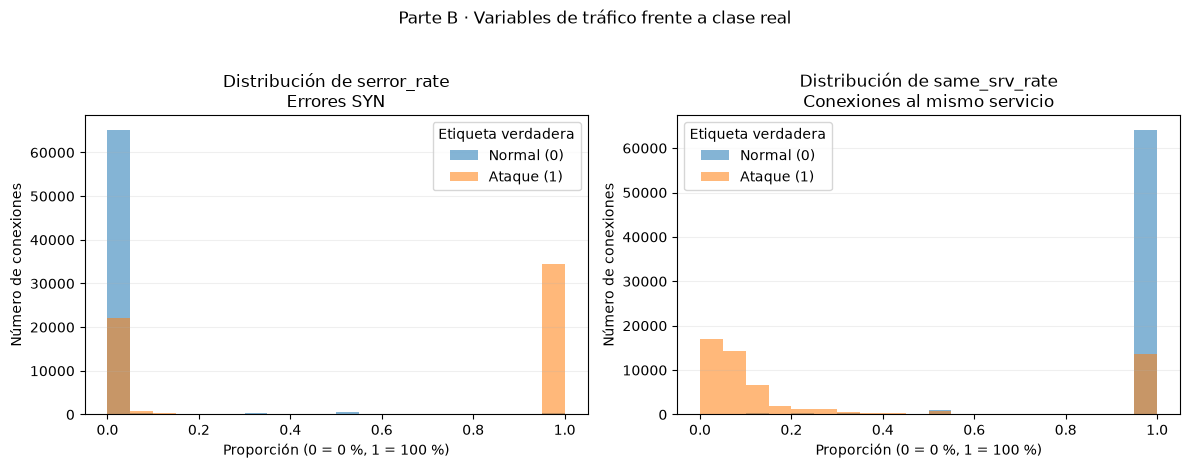

In [6]:
import matplotlib.pyplot as plt
import numpy as np

# Dividimos el rango 0–1 en 20 intervalos iguales para ambas clases.
limites_intervalos = np.linspace(0, 1, 21)
variables_grafico = {
    "serror_rate": "Errores SYN",
    "same_srv_rate": "Conexiones al mismo servicio",
}

figura, ejes = plt.subplots(1, 2, figsize=(12, 4.5))

for eje, (columna, descripcion) in zip(ejes, variables_grafico.items()):
    # Dos subconjuntos de la misma columna, separados por etiqueta real.
    for clase, texto_clase in [(0, "Normal (0)"), (1, "Ataque (1)")]:
        valores_clase = df.loc[df["is_attack"] == clase, columna]
        eje.hist(
            valores_clase,
            bins=limites_intervalos,
            alpha=0.55,  # Transparencia: permite ver barras solapadas.
            label=texto_clase,
        )
    eje.set_title(f"Distribución de {columna}\n{descripcion}")
    eje.set_xlabel("Proporción (0 = 0 %, 1 = 100 %)")
    eje.set_ylabel("Número de conexiones")
    eje.legend(title="Etiqueta verdadera")
    eje.grid(axis="y", alpha=0.2)

figura.suptitle("Parte B · Variables de tráfico frente a clase real", y=1.03)
plt.tight_layout()
plt.show()

**Lectura razonada:** valores altos de `serror_rate` son frecuentes en ciertos ataques de denegación de servicio como `neptune`, porque las conexiones presentan muchos errores de establecimiento TCP. Pero **no todo ataque es un SYN flood**: algunas conexiones maliciosas pueden tener `serror_rate=0`. `same_srv_rate` aporta otro ángulo sobre el patrón de conexiones; la combinación de señales puede resultar más útil que cualquiera por separado.

**Observación frente a hipótesis:** el gráfico permite observar si hay acumulaciones y solapamientos en *este dataset*. La hipótesis «una tasa alta de errores implica ataque» debe **evaluarse**, no darse por demostrada por el dibujo. Ese es el objetivo de la Parte C.

## Parte C · Comparar una regla escrita a mano con un árbol entrenado

**Objetivo:** ver la diferencia esencial entre «el analista fija una condición» y «el algoritmo escoge las condiciones examinando ejemplos etiquetados».

Nuestra **regla manual** es: «marcar como ataque (`1`) toda conexión con `serror_rate > 0,5`». Un valor `0,5` equivale al **50 %** de errores SYN. Si una conexión tiene `0,8`, la regla da `1`; si tiene `0,2`, da `0`. El umbral es una elección humana, **no** un valor aprendido.

Para evaluar necesitamos dos listas de igual tamaño: **respuesta verdadera** (`df["is_attack"]`) y **predicción** (`prediccion_regla`). La **exactitud** (*accuracy*) mide la proporción total de aciertos:

$$\text{accuracy}=\frac{\text{predicciones correctas}}{\text{todas las conexiones}}=\frac{VP+VN}{VP+VN+FP+FN}.$$

Para entender qué errores se están cometiendo se usa una **matriz de confusión**, una tabla de **clase real** frente a **clase predicha**:

| | Predicción normal (`0`) | Predicción ataque (`1`) |
|---|---|---|
| **Real normal (`0`)** | **VN**: verdadero negativo, normal bien clasificado | **FP**: falso positivo, falsa alarma |
| **Real ataque (`1`)** | **FN**: falso negativo, ataque que no se detecta | **VP**: verdadero positivo, ataque detectado |

«Positivo» significa «ataque», no «bueno»; «negativo» significa «normal». Una exactitud alta puede ocultar muchos FN cuando los ataques son raros. Por eso mostraremos **la matriz además de la exactitud**.

In [7]:
from sklearn.metrics import accuracy_score, confusion_matrix

# Regla fija: una comparación por fila devuelve True o False;
# .astype(int) lo traduce a 1 (alerta) o 0 (normal).
prediccion_regla = (df["serror_rate"] > 0.5).astype(int)
verdad_entrenamiento = df["is_attack"]

# accuracy_score compara las dos listas posición a posición.
exactitud_regla = accuracy_score(verdad_entrenamiento, prediccion_regla)

# Orden explícito [0, 1]: filas = verdad, columnas = predicción.
matriz_regla = confusion_matrix(
    verdad_entrenamiento, prediccion_regla, labels=[0, 1]
)
matriz_legible = pd.DataFrame(
    matriz_regla,
    index=["Real: normal (0)", "Real: ataque (1)"],
    columns=["Predicho: normal (0)", "Predicho: ataque (1)"],
)

print("=" * 70)
print("PARTE C · Regla fija: serror_rate > 0,5")
print("=" * 70)
print(f"Exactitud sobre entrenamiento: {exactitud_regla:.4f} ({exactitud_regla:.2%})")
print("\nMatriz de confusión · filas = realidad; columnas = decisión:")
display(matriz_legible)
print(f"VN (normal correcto): {matriz_regla[0, 0]:,}".replace(",", "."))
print(f"FP (falsas alarmas): {matriz_regla[0, 1]:,}".replace(",", "."))
print(f"FN (ataques omitidos): {matriz_regla[1, 0]:,}".replace(",", "."))
print(f"VP (ataques detectados): {matriz_regla[1, 1]:,}".replace(",", "."))

PARTE C · Regla fija: serror_rate > 0,5
Exactitud sobre entrenamiento: 0.8076 (80.76%)

Matriz de confusión · filas = realidad; columnas = decisión:


,Predicho: normal (0),Predicho: ataque (1)
Real: normal (0),66906,437
Real: ataque (1),23800,34830


VN (normal correcto): 66.906
FP (falsas alarmas): 437
FN (ataques omitidos): 23.800
VP (ataques detectados): 34.830


**Interpretación:** la exactitud indica el porcentaje de conexiones correctamente clasificadas **en el mismo archivo usado para examinar y definir la regla**. Es una evaluación inicial, **no** una estimación de rendimiento en redes nuevas. En la matriz, la celda **Real: ataque / Predicho: normal** es especialmente importante: cuenta ataques que no generan alerta. Un analista puede preferir reducir esos FN, pero debe vigilar también las falsas alarmas FP.

**Ejemplo numérico para leer cualquier matriz:** si hubiese `90 VN`, `5 FP`, `3 FN` y `2 VP`, la exactitud sería `(90+2)/100 = 92 %`, pero solo se detectarían `2/(2+3) = 40 %` de los ataques. La matriz explica lo que la exactitud por sí sola esconde.

### C.1 · Aprender un umbral: un árbol con una sola pregunta

Un **árbol de decisión** aprende preguntas del tipo «¿`columna <= valor`?» para dividir los registros en grupos. En cada división busca una separación más útil de las etiquetas. Un árbol con `max_depth=1` solo puede hacer **una división**, por eso se llama *decision stump* (tocón). Puede elegir **qué variable** utilizar y **qué umbral** aplicar, sin que el analista los escriba.

Aquí le permitimos observar exactamente **tres características**: `serror_rate`, `same_srv_rate` y `count` (cantidad de conexiones recientes al mismo destino). `X` representa las **entradas** y `y` la **respuesta verdadera**. `fit(X, y)` aprende la pregunta; `.score(X, y)` calcula la exactitud en el mismo conjunto. `random_state=0` fija la semilla para reproducibilidad. **No introducimos `label` ni `is_attack` en X**: serían respuestas disfrazadas de entradas.

**Importante:** aprender una regla no significa conocer la causa del ataque. El árbol puede descubrir una asociación estadística útil en este archivo, no una ley universal de ciberseguridad.

In [8]:
from sklearn.tree import DecisionTreeClassifier, export_text

# Cada fila de X contiene tres mediciones de la misma conexión.
# y contiene la respuesta que el árbol debe aprender a aproximar.
X = df[["serror_rate", "same_srv_rate", "count"]]
y = df["is_attack"]

# max_depth=1: una división como máximo. La semilla hace reproducible el ajuste.
arbol_simple = DecisionTreeClassifier(max_depth=1, random_state=0)
arbol_simple.fit(X, y)

# export_text imprime las condiciones aprendidas y la clase de cada rama.
regla_aprendida = export_text(arbol_simple, feature_names=list(X.columns))
exactitud_arbol_simple = arbol_simple.score(X, y)

print("=" * 70)
print("PARTE C · Árbol de decisión de profundidad 1")
print("=" * 70)
print("Regla aprendida a partir de las 3 características:")
print(regla_aprendida)
print("Leyenda: class: 0 = normal; class: 1 = ataque")
print(f"\nExactitud en entrenamiento: {exactitud_arbol_simple:.4f} ({exactitud_arbol_simple:.2%})")
print(f"Exactitud de la regla manual: {exactitud_regla:.4f} ({exactitud_regla:.2%})")

PARTE C · Árbol de decisión de profundidad 1
Regla aprendida a partir de las 3 características:
|--- same_srv_rate <= 0.50
|   |--- class: 1
|--- same_srv_rate >  0.50
|   |--- class: 0

Leyenda: class: 0 = normal; class: 1 = ataque

Exactitud en entrenamiento: 0.8677 (86.77%)
Exactitud de la regla manual: 0.8076 (80.76%)


**Cómo leer el árbol:** `|--- variable <= umbral` es la pregunta; las ramas indentadas indican qué sucede si la condición se cumple o no. `class: 0` y `class: 1` son las etiquetas predichas en los dos grupos. El algoritmo elige la partición automáticamente; el umbral que aparezca es un **resultado aprendido**, no algo que tengamos que escribir antes.

**Comparación justa, con una limitación:** podemos comparar aquí la exactitud de la regla manual y el tocón porque usan el mismo conjunto, pero el árbol **se entrenó sobre esas filas**, mientras que el umbral manual se escogió sin optimización automática. Por tanto, esta comparación ilustra el mecanismo del aprendizaje, **no demuestra** que el árbol vaya a funcionar mejor con tráfico futuro.

### C.2 · ¿Qué cambia cuando un árbol puede hacer más preguntas?

`max_depth` limita la **profundidad** de las preguntas sucesivas. Con profundidad `2`, puede preguntar algo distinto dentro de cada rama; con profundidad `8`, puede crear condiciones mucho más específicas. Se mantienen las **mismas tres características** y las **mismas filas**; solo cambia la complejidad permitida.

**Qué observar:** la columna «Exactitud en entrenamiento» describe el ajuste a estos datos ya conocidos. Si aumenta con la profundidad, **todavía no** podemos afirmar que el modelo haya mejorado en tráfico nuevo. Necesitamos una prueba separada, que llegará en la Parte D.

In [9]:
resultados_arboles_pequenos = []

for profundidad in [2, 4, 8]:
    # Nuevo árbol para cada profundidad; todos ven exactamente los mismos X e y.
    arbol = DecisionTreeClassifier(max_depth=profundidad, random_state=0)
    arbol.fit(X, y)
    resultados_arboles_pequenos.append({
        "Profundidad máxima": profundidad,
        "Exactitud en entrenamiento": arbol.score(X, y),
    })

comparacion_arboles_pequenos = pd.DataFrame(resultados_arboles_pequenos)
print("=" * 65)
print("PARTE C · Profundidad frente a ajuste a datos conocidos")
print("=" * 65)
display(comparacion_arboles_pequenos)

PARTE C · Profundidad frente a ajuste a datos conocidos


,Profundidad máxima,Exactitud en entrenamiento
0,2,0.887015
1,4,0.896565
2,8,0.900939


**Pregunta original: ¿qué detecta el árbol que tu regla no ve? ¿Qué ocurre con la explicabilidad?**

La regla manual solo observa si `serror_rate > 0,5`. Un árbol puede **escoger otro umbral o variable** entre `serror_rate`, `same_srv_rate` y `count`; con más profundidad puede combinar condiciones y separar conexiones que la regla simple trata como iguales. Mira la regla impresa para saber **qué característica eligió realmente el árbol de profundidad 1**: no des por hecho que utilizó las tres.

A mayor profundidad, hay potencialmente más grupos y combinaciones de condiciones, lo cual puede mejorar el ajuste, pero **cuesta más explicar una predicción concreta** y aumenta el riesgo de memorizar patrones del entrenamiento. Un árbol pequeño suele entenderse leyendo sus ramas; uno profundo puede tener muchísimas. Esta relación entre flexibilidad y facilidad de explicación es una **contrapartida**, no una garantía de que un árbol profundo siempre sea peor.

## Parte D · Entrenar con un archivo y probar con otro

**Objetivo:** evaluar si lo aprendido con ejemplos conocidos también funciona ante registros no utilizados para entrenar. **Generalizar** significa mantener un rendimiento útil en datos nuevos representativos del problema, no solo recordar los ejemplos ya vistos.

- **Entrenamiento (`KDDTrain+.txt`):** el modelo puede consultar entradas y etiquetas para ajustar sus decisiones.
- **Prueba (`KDDTest+.txt`):** el modelo recibe las entradas **sin ajustar sus reglas con sus respuestas**; las etiquetas del test solo se usan para calcular la puntuación al terminar.

Usaremos **13 variables numéricas**, seleccionadas en el cuaderno original (duración, bytes, contadores y tasas). Esta selección evita introducir variables categóricas que necesitarían codificación, pero también excluye información potencialmente útil como `protocol_type`. No significa que 13 sean «las mejores» características.

Entrenamos ocho árboles con profundidades `1, 2, 3, 5, 8, 12, 20` y `None` (sin límite explícito de profundidad). Para cada uno calculamos *accuracy de entrenamiento* y *accuracy de prueba*. **No confundas probar el modelo con entrenarlo otra vez**: `score(test_X, test_y)` calcula aciertos, no modifica el árbol.

In [10]:
# La función de la Parte A carga archivos distintos; no mezcla sus filas.
datos_entrenamiento = load_nsl_kdd("train")
datos_prueba = load_nsl_kdd("test")

# Son EXACTAMENTE las 13 entradas del ejercicio original, en el mismo orden.
caracteristicas = [
    "duration", "src_bytes", "dst_bytes", "count", "srv_count",
    "serror_rate", "rerror_rate", "same_srv_rate", "diff_srv_rate",
    "dst_host_count", "dst_host_srv_count",
    "dst_host_same_srv_rate", "logged_in",
]

X_entrenamiento = datos_entrenamiento[caracteristicas]
y_entrenamiento = datos_entrenamiento["is_attack"]
X_prueba = datos_prueba[caracteristicas]
y_prueba = datos_prueba["is_attack"]

print("=" * 70)
print("PARTE D · Conjuntos separados")
print("=" * 70)
print(f"Entrenamiento: {len(X_entrenamiento):,} conexiones, {len(caracteristicas)} entradas por conexión".replace(",", "."))
print(f"Prueba:        {len(X_prueba):,} conexiones, {len(caracteristicas)} entradas por conexión".replace(",", "."))
print("Etiquetas esperadas: 0 = normal, 1 = ataque")
print(f"Proporción de ataques en entrenamiento: {y_entrenamiento.mean():.2%}")
print(f"Proporción de ataques en prueba:        {y_prueba.mean():.2%}")

# Misma técnica y semilla; solo varía la profundidad máxima permitida.
filas_resultados = []
for profundidad in [1, 2, 3, 5, 8, 12, 20, None]:
    modelo_arbol = DecisionTreeClassifier(max_depth=profundidad, random_state=0)
    modelo_arbol.fit(X_entrenamiento, y_entrenamiento)
    filas_resultados.append({
        "max_depth": str(profundidad),
        "acc_train": modelo_arbol.score(X_entrenamiento, y_entrenamiento),
        "acc_test": modelo_arbol.score(X_prueba, y_prueba),
    })

# La tabla mantiene los valores numéricos originales (entre 0 y 1).
resultados_profundidad = pd.DataFrame(filas_resultados)
print("\n" + "-" * 70)
print("EXACTITUD SEGÚN COMPLEJIDAD · Valores de 0 (0 %) a 1 (100 %)")
print("-" * 70)
display(resultados_profundidad.rename(columns={
    "max_depth": "Profundidad máxima",
    "acc_train": "Exactitud entrenamiento",
    "acc_test": "Exactitud prueba",
}))

PARTE D · Conjuntos separados
Entrenamiento: 125.973 conexiones. 13 entradas por conexión
Prueba:        22.544 conexiones. 13 entradas por conexión
Etiquetas esperadas: 0 = normal, 1 = ataque
Proporción de ataques en entrenamiento: 46.54%
Proporción de ataques en prueba:        56.92%

----------------------------------------------------------------------
EXACTITUD SEGÚN COMPLEJIDAD · Valores de 0 (0 %) a 1 (100 %)
----------------------------------------------------------------------


,Profundidad máxima,Exactitud entrenamiento,Exactitud prueba
0,1,0.922150,0.799858
1,2,0.947497,0.768941
2,3,0.960690,0.791652
3,5,0.974526,0.776482
4,8,0.993197,0.774264
5,12,0.997912,0.768408
6,20,0.999714,0.771026
7,None,0.999762,0.771647


### D.1 · Visualizar el ajuste frente a la generalización

Dibujamos las **mismas ocho puntuaciones**, sin recalcular ni suavizar valores. En el eje horizontal aparecen las profundidades comparadas; `None` significa «sin límite de profundidad». En el eje vertical, la exactitud entre `0` y `1` (donde `1 = 100 %`). Cada punto representa **un árbol entrenado**.

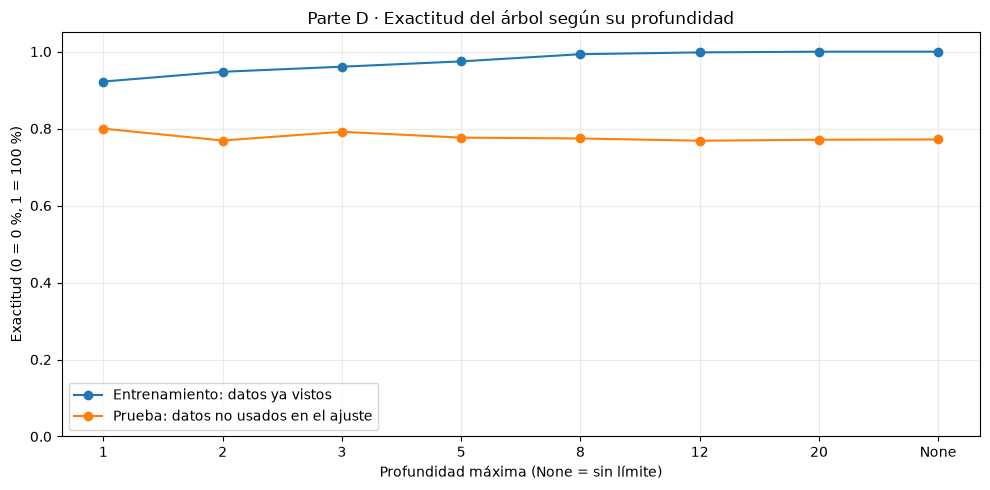

In [11]:
figura, eje = plt.subplots(figsize=(10, 5))

# Las dos líneas usan la misma secuencia de profundidades, para que sean comparables.
eje.plot(
    resultados_profundidad["max_depth"],
    resultados_profundidad["acc_train"],
    marker="o",
    label="Entrenamiento: datos ya vistos",
)
eje.plot(
    resultados_profundidad["max_depth"],
    resultados_profundidad["acc_test"],
    marker="o",
    label="Prueba: datos no usados en el ajuste",
)

eje.set_title("Parte D · Exactitud del árbol según su profundidad")
eje.set_xlabel("Profundidad máxima (None = sin límite)")
eje.set_ylabel("Exactitud (0 = 0 %, 1 = 100 %)")
eje.set_ylim(0, 1.05)
eje.legend()
eje.grid(alpha=0.25)
plt.tight_layout()
plt.show()

### D.2 · Resultado e interpretación (respuesta desarrollada al ejercicio)

1. **La curva de entrenamiento** normalmente aumenta con la profundidad: un árbol flexible puede separar más casos de los que ya vio y acercarse a una exactitud de `1` (100 %).
2. **La curva de prueba** no tiene por qué crecer a la vez: las condiciones que encajan con el entrenamiento pueden no servir para las conexiones de `KDDTest+`. En este benchmark suele observarse una exactitud de prueba bastante inferior a la de entrenamiento; lee **los valores ejecutados** de la tabla, no tomes un intervalo aproximado como garantía.
3. **Sobreajuste** (*overfitting*) significa ajustar tan bien las particularidades del entrenamiento que se perjudica el rendimiento fuera de esos datos. Una brecha persistente entre entrenamiento y prueba **es compatible** con sobreajuste, pero **no demuestra por sí sola** que sea su única causa.
4. **Cambio de distribución:** los archivos oficiales de NSL-KDD tienen distintas proporciones de clases y en el test aparecen tipos de ataque no presentes en el entrenamiento. Ese cambio también puede explicar parte de la brecha. Por tanto, decir que «toda la diferencia es sobreajuste» sería una conclusión demasiado fuerte.
5. **Elección del modelo:** no debemos elegir la mejor profundidad mirando repetidamente los resultados del conjunto final de prueba, porque acabaríamos usándolo indirectamente para tomar decisiones. Se prepara un conjunto de **validación** separado (o validación cruzada) para seleccionar parámetros; el **test** queda reservado para la evaluación final.

**Conclusión operativa:** una exactitud casi perfecta sobre datos conocidos no demuestra que un detector vaya a funcionar igual frente a tráfico nuevo. En un SOC también habrá que estudiar falsos positivos, falsos negativos y cambios de comportamiento, no solo la exactitud global.

## Parte E · La tasa base: por qué un detector «bueno» puede inundar un SOC

**Objetivo:** entender qué ocurriría al aplicar un detector a una red donde los ataques son muy poco frecuentes. No entrenaremos otro modelo: haremos una **simulación aritmética** manteniendo los valores originales del ejercicio.

Supón **1.000.000 eventos**, una **tasa base de ataque de `0,0001` (0,01 %)** y un detector con:

- **TPR / sensibilidad / recall = `0,99` (99 %):** de cada 100 ataques verdaderos, detecta 99. Fórmula: `VP / (VP + FN)`.
- **FPR / tasa de falsas alarmas = `0,01` (1 %):** de cada 100 eventos normales, marca erróneamente uno. Fórmula: `FP / (FP + VN)`.
- **Precisión / precision:** de **todas las alertas emitidas**, qué fracción era realmente un ataque. Fórmula: `VP / (VP + FP)`.

**Tres denominadores distintos**: TPR parte de los ataques reales; FPR parte de los eventos normales; precisión parte de las **alertas**. Por eso **TPR del 99 % no significa que el 99 % de las alertas sean verdaderas**.

La función `alertas(n_eventos, tasa_base, tpr, fpr)` calcula **cantidades esperadas**: `ataques = eventos × tasa_base`, `VP = ataques × TPR`, `FP = normales × FPR` y `precisión = VP/(VP+FP)`. Pueden aparecer decimales porque son valores matemáticos esperados, no un recuento observado de personas o alertas individuales.

In [12]:
def alertas(n_eventos, tasa_base, tpr, fpr):
    """Calcula alertas y precisión esperadas sin entrenar un modelo.

    n_eventos: total de conexiones o eventos.
    tasa_base: proporción real de ataques, en el intervalo [0, 1].
    tpr: proporción de ataques detectados, en [0, 1].
    fpr: proporción de eventos normales que producen falsa alarma, en [0, 1].
    """
    # Primero separamos eventos maliciosos de eventos normales.
    ataques = n_eventos * tasa_base
    normales = n_eventos - ataques

    # Cada tasa afecta a un grupo distinto de eventos.
    vp = ataques * tpr
    fp = normales * fpr
    numero_alertas = vp + fp

    # Solo las alertas verdaderas cuentan como aciertos para la precisión.
    # Como en la función original, se supone que el detector emite alguna alerta.
    return {
        "tp": vp,  # True positives: verdaderos positivos.
        "fp": fp,  # False positives: falsos positivos.
        "precision": vp / numero_alertas,
        "alertas": numero_alertas,
    }

n_eventos = 1_000_000
tasa_base = 0.0001
tpr = 0.99
fpr_inicial = 0.01
resultado_inicial = alertas(n_eventos, tasa_base, tpr, fpr_inicial)

print("=" * 70)
print("PARTE E · Simulación con 1.000.000 de eventos")
print("=" * 70)
print(f"Eventos: {n_eventos:,}".replace(",", "."))
print(f"Tasa real de ataques: {tasa_base:.4%}")
print(f"TPR (ataques detectados): {tpr:.2%}")
print(f"FPR (normales que generan alarma): {fpr_inicial:.2%}")
print(f"Ataques reales esperados: {n_eventos * tasa_base:,.0f}".replace(",", "."))
print(f"Verdaderos positivos (VP): {resultado_inicial['tp']:.2f} eventos")
print(f"Falsos positivos (FP): {resultado_inicial['fp']:.2f} eventos")
print(f"Total de alertas: {resultado_inicial['alertas']:.2f} eventos")
print(f"Precisión de las alertas: {resultado_inicial['precision']:.4%}")

# Manteniendo el resto idéntico, solo cambiamos FPR en el mismo escenario.
filas_fpr = []
for fpr in [0.1, 0.01, 0.001, 0.0001]:
    resultado = alertas(n_eventos, tasa_base, tpr, fpr)
    filas_fpr.append({
        "FPR": fpr,
        "VP esperados": resultado["tp"],
        "FP esperados": resultado["fp"],
        "Alertas esperadas": resultado["alertas"],
        "Precisión": resultado["precision"],
    })

print("\n" + "-" * 70)
print("COMPARACIÓN · Solo cambia la tasa de falsos positivos (FPR)")
print("-" * 70)
tabla_fpr = pd.DataFrame(filas_fpr)
display(tabla_fpr)

PARTE E · Simulación con 1.000.000 de eventos
Eventos: 1.000.000
Tasa real de ataques: 0.0100%
TPR (ataques detectados): 99.00%
FPR (normales que generan alarma): 1.00%
Ataques reales esperados: 100
Verdaderos positivos (VP): 99.00 eventos
Falsos positivos (FP): 9999.00 eventos
Total de alertas: 10098.00 eventos
Precisión de las alertas: 0.9804%

----------------------------------------------------------------------
COMPARACIÓN · Solo cambia la tasa de falsos positivos (FPR)
----------------------------------------------------------------------


,FPR,VP esperados,FP esperados,Alertas esperadas,Precisión
0,0.1000,99.0,99990.00,100089.00,0.000989
1,0.0100,99.0,9999.00,10098.00,0.009804
2,0.0010,99.0,999.90,1098.90,0.090090
3,0.0001,99.0,99.99,198.99,0.497512


### E.1 · Resolución numérica e interpretación

Con **1.000.000** de eventos y **0,01 %** de ataques, esperamos `100` ataques y `999.900` eventos normales. Si TPR = `99 %`, el detector alerta sobre `99` ataques. Con FPR = `1 %`, también alerta sobre **9.999** eventos normales. Hay **10.098 alertas**, pero solo **99** son ataques: precisión `99 / 10.098 ≈ 0,98 %`. ¡El detector reconoce casi todos los ataques y, aun así, casi todas sus alertas son falsas!

**Pregunta original: ¿qué FPR permite alcanzar al menos un 50 % de precisión?** Para que la mitad de las alertas sean correctas deben cumplirse `VP ≥ FP`. Como `VP = N × base × TPR` y `FP = N × (1 − base) × FPR`, despejamos:

$$\mathrm{FPR}\leq\frac{\mathrm{base}\times\mathrm{TPR}}{1-\mathrm{base}}=\frac{0,0001\times0,99}{0,9999}\approx 0,00009901.$$

Eso es **FPR ≤ 0,009901 %**, aproximadamente **una falsa alarma por cada 10.100 eventos normales**. Atención: `0,0001` expresado como proporción equivale a `0,01 %` y resulta *ligeramente superior* al límite; con esa FPR la precisión queda **justo por debajo** del 50 %.

**Tres conclusiones para un SOC:**

1. El número de eventos normales es enorme; incluso una FPR aparentemente pequeña puede producir miles de falsas alarmas y consumir el tiempo de los analistas.
2. Una regla manual o un modelo ML deben compararse con **TPR, FPR y precisión a la tasa base real**, además de tener en cuenta el coste de perder un ataque; «ML» no significa automáticamente mejores alertas.
3. Antes de bloquear automáticamente o desplegar un modelo, hay que estimar la prevalencia real de ataques, validar alertas y ajustar umbrales o combinaciones de señales según las necesidades del SOC.

In [13]:
# Comprobación directa del resultado algebraico del ejercicio.
fpr_limite = tasa_base * tpr / (1 - tasa_base)
resultado_limite = alertas(n_eventos, tasa_base, tpr, fpr_limite)

print("=" * 68)
print("PARTE E · Umbral matemático para alcanzar un 50 % de precisión")
print("=" * 68)
print(f"FPR máxima permitida (proporción): {fpr_limite:.10f}")
print(f"FPR máxima permitida (porcentaje): {fpr_limite:.6%}")
print(f"Precisión en el límite: {resultado_limite['precision']:.2%}")
print(f"VP y FP esperados: {resultado_limite['tp']:.2f} y {resultado_limite['fp']:.2f}")

PARTE E · Umbral matemático para alcanzar un 50 % de precisión
FPR máxima permitida (proporción): 0.0000990099
FPR máxima permitida (porcentaje): 0.009901%
Precisión en el límite: 50.00%
VP y FP esperados: 99.00 y 99.00


## Parte F · Diseñar un caso de uso (ejercicio por parejas, resuelto)

**Objetivo:** antes de decir «vamos a usar ML», precisar **qué queremos detectar, con qué datos, de dónde sale la verdad y qué errores importan**. La ficha original se conserva y se completa con un ejemplo defendible en una exposición de dos minutos. El resultado es un **diseño**, no un detector ya desplegado.

**Caso elegido: detección de denegación de servicio en tráfico de red.** Una denegación de servicio (DoS) busca dificultar o impedir el uso de un servicio, por ejemplo provocando muchas conexiones o paquetes que agotan recursos. Las señales posibles incluyen volúmenes de tráfico, frecuencia de conexiones y tasas de error; una señal sola no basta para confirmar un incidente.

| Campo del ejercicio | Respuesta desarrollada y justificación |
|---|---|
| **Ámbito elegido** | Detección y priorización de posibles ataques de **denegación de servicio** sobre un servicio de red. Es medible mediante características de conexiones. |
| **Datos: ¿qué fuente usaríais?** | **NetFlow/IPFIX** o registros de **Zeek (`conn.log`)** con conexiones, marcas de tiempo, origen, destino, duración, bytes y estado. De esos registros se pueden calcular tasas de conexiones por intervalo. La granularidad y disponibilidad dependen del sensor. |
| **Etiqueta: ¿qué es positivo y de dónde sale?** | `1` = conexión/ventana asociada a un incidente DoS confirmado; `0` = tráfico normal revisado. Las etiquetas pueden proceder de simulaciones controladas y de incidentes validados por analistas. No basta asumir que «muchas conexiones = ataque». |
| **Error caro: ¿falso negativo o falso positivo?** | Un **FN** permite pasar un DoS real y afecta a la disponibilidad. Un **FP** puede interrumpir tráfico legítimo si aplicamos un bloqueo automático. La gravedad relativa depende de la acción asociada a la alerta; con bloqueo, el FP puede ser especialmente costoso. |
| **Dataset público para empezar** | **NSL-KDD** permite practicar con `neptune` y otras etiquetas de ataque. Sus datos están anticuados: no deben tomarse como prueba de rendimiento en una infraestructura moderna. |
| **Evasión: ¿cómo engañaría un atacante al modelo?** | Podría distribuir el tráfico entre varios orígenes o reducir su tasa por origen para evitar reglas basadas en grandes picos. Es una **hipótesis de evasión** que habría que poner a prueba, no una evasión demostrada de nuestro modelo. |
| **Técnicas ATT&CK que cubriría** | [T1498 · Network Denial of Service](https://attack.mitre.org/techniques/T1498/) es una referencia pertinente. **Cobertura potencial** no equivale a capacidad demostrada de detectar todas sus variantes. |

**Guion de exposición (dos minutos):** «Queremos identificar posibles DoS a partir de tasas de conexiones y errores registrados por un sensor. Etiquetaríamos ventanas mediante pruebas controladas e incidentes validados. Mediríamos falsos negativos para no omitir ataques y falsos positivos para evitar bloqueos injustificados. Empezaríamos con reglas interpretables y compararíamos un modelo sobre datos separados de entrenamiento y validación. Evaluaríamos la deriva del tráfico y sus consecuencias operativas antes de ponerlo en producción».

## Parte G · Aprender un umbral sin `scikit-learn`

**Objetivo:** descubrir que «aprender» puede consistir en buscar, mediante un procedimiento sencillo, el valor de una regla que comete menos errores. No hace falta una red neuronal para eso.

Tenemos **cuatro flujos sintéticos**. La variable `cps` significa «conexiones por segundo»; las etiquetas `y4` son sus clases reales:

| Flujo | Conexiones por segundo (`cps`) | Etiqueta real (`y4`) |
|---|---:|---|
| 1 | 2 | 0 = normal |
| 2 | 3 | 0 = normal |
| 3 | 40 | 1 = ataque |
| 4 | 55 | 1 = ataque |

Nuestra regla será siempre: **«ataque si `cps > t`»**. Lo único que se aprende es el **umbral `t`**. Candidatos razonables: un valor por debajo del mínimo, los puntos medios entre valores consecutivos ordenados y otro por encima del máximo. Entre `3` y `40` el punto medio es `(3 + 40)/2 = 21,5`.

`np.array([...])` crea un vector de números; `cps[:-1]` contiene todos menos el último, `cps[1:]` todos menos el primero, y su suma/2 calcula puntos medios entre vecinos. `np.r_` concatena los candidatos. En el código, `prediccion != etiquetas` produce `True` donde se comete un error y `.sum()` cuenta esos errores.

In [14]:
# Cuatro conexiones por segundo y sus etiquetas reales (0 normal, 1 ataque).
cps = np.array([2, 3, 40, 55])
y4 = np.array([0, 0, 1, 1])

# Candidatos originales: extremo inferior, puntos medios y extremo superior.
candidatos = np.r_[
    cps.min() - 1,
    (cps[:-1] + cps[1:]) / 2,
    cps.max() + 1,
]

resultados_umbrales = []
for umbral in candidatos:
    # La misma regla se evalúa en los cuatro flujos; ninguna biblioteca la entrena.
    prediccion = (cps > umbral).astype(int)
    falsos_positivos = int(((prediccion == 1) & (y4 == 0)).sum())
    falsos_negativos = int(((prediccion == 0) & (y4 == 1)).sum())
    resultados_umbrales.append({
        "Umbral t (conexiones/s)": umbral,
        "Falsos positivos (FP)": falsos_positivos,
        "Falsos negativos (FN)": falsos_negativos,
        "Errores totales": int((prediccion != y4).sum()),
    })

tabla_umbrales = pd.DataFrame(resultados_umbrales)
print("=" * 70)
print("PARTE G · Búsqueda de umbral con 4 flujos")
print("=" * 70)
print("Regla: ataque (1) si las conexiones por segundo superan t")
print("Datos: 2→normal, 3→normal, 40→ataque, 55→ataque")
display(tabla_umbrales)

# idxmin selecciona la primera fila donde los errores totales son mínimos.
mejor_umbral = tabla_umbrales.loc[tabla_umbrales["Errores totales"].idxmin(),
                                 "Umbral t (conexiones/s)"]
print(f"Mejor umbral entre los candidatos: t = {mejor_umbral:g} conexiones/s")

PARTE G · Búsqueda de umbral con 4 flujos
Regla: ataque (1) si las conexiones por segundo superan t
Datos: 2→normal, 3→normal, 40→ataque, 55→ataque


,Umbral t (conexiones/s),Falsos positivos (FP),Falsos negativos (FN),Errores totales
0,1.0,2,0,2
1,2.5,1,0,1
2,21.5,0,0,0
3,47.5,0,1,1
4,56.0,0,2,2


Mejor umbral entre los candidatos: t = 21.5 conexiones/s


### G.1 · Primera respuesta: ¿cuántos umbrales tienen cero errores y cuál elegir?

En los **cinco candidatos evaluados** (`1`, `2,5`, `21,5`, `47,5`, `56`) **solo `t = 21,5`** obtiene cero errores. Con ese umbral, `2` y `3` quedan por debajo (normal) y `40` y `55` por encima (ataque). **También** serviría cualquier umbral real entre `3` (incluido) y `40` (excluido); no afirmamos que `21,5` sea el único número posible, sino el único **candidato** con cero errores.

**Por qué elegir `21,5`:** es el punto medio de los dos valores vecinos más próximos **con etiquetas diferentes** (`3` normal y `40` ataque). Queda margen entre ambas clases observadas. Eso no garantiza que funcione con nuevos flujos de velocidades intermedias.

### G.2 · Quinto flujo y errores con distinto coste

El ejercicio pide incorporar el flujo `cps=25`, **etiqueta ataque (`1`)**, y **penalizar el falso negativo cinco veces más** que un falso positivo. Un falso negativo (FN) es un ataque predicho como normal; un falso positivo (FP) es tráfico normal marcado como ataque.

**Nueva pérdida o coste:** `coste = 1 × FP + 5 × FN`. Por ejemplo, si una regla produce `1 FP` y `0 FN`, su coste es `1`; si produce `0 FP` y `1 FN`, su coste es `5`. La **suma de errores** cuenta ambos por igual; el **coste ponderado** reconoce que un ataque omitido nos preocupa más en este escenario ficticio.

Al añadir `25` es indispensable **ordenar los valores de `cps` junto con sus etiquetas** antes de recalcular los puntos medios; si no, estaríamos comparando valores que no son vecinos numéricos. Solo estamos completando el ejercicio: la regla, los datos originales y el mecanismo de candidatos se mantienen.

In [15]:
# Añadimos el quinto flujo solicitado, sin modificar los cuatro originales.
cps_cinco = np.append(cps, 25)
etiquetas_cinco = np.append(y4, 1)  # 25 conexiones/s es ataque.

# Ordenamos ambos arrays con LOS MISMOS índices para conservar cada etiqueta.
orden = np.argsort(cps_cinco)
cps_ordenados = cps_cinco[orden]
etiquetas_ordenadas = etiquetas_cinco[orden]

# Repetimos la generación de candidatos con los cinco flujos ordenados.
candidatos_cinco = np.r_[
    cps_ordenados.min() - 1,
    (cps_ordenados[:-1] + cps_ordenados[1:]) / 2,
    cps_ordenados.max() + 1,
]

filas_costes = []
for umbral in candidatos_cinco:
    prediccion = (cps_ordenados > umbral).astype(int)
    fp = int(((prediccion == 1) & (etiquetas_ordenadas == 0)).sum())
    fn = int(((prediccion == 0) & (etiquetas_ordenadas == 1)).sum())
    filas_costes.append({
        "Umbral t (conexiones/s)": umbral,
        "FP": fp,
        "FN": fn,
        "Errores sin ponderar (FP + FN)": fp + fn,
        "Coste ponderado (FP + 5×FN)": fp + 5 * fn,
    })

tabla_costes = pd.DataFrame(filas_costes)
mejor_fila_coste = tabla_costes.loc[tabla_costes["Coste ponderado (FP + 5×FN)"].idxmin()]

print("=" * 75)
print("PARTE G · 5 flujos, falso negativo con coste 5")
print("=" * 75)
descripcion_flujos = ", ".join(
    f"{int(conexiones)} cps → {'ataque (1)' if clase == 1 else 'normal (0)'}"
    for conexiones, clase in zip(cps_ordenados, etiquetas_ordenadas)
)
print(f"Flujos ordenados: {descripcion_flujos}")
print("Coste = FP + 5 × FN")
display(tabla_costes)
print(f"Umbral de menor coste entre candidatos: {mejor_fila_coste['Umbral t (conexiones/s)']:g} conexiones/s")
print(f"Coste mínimo alcanzado: {mejor_fila_coste['Coste ponderado (FP + 5×FN)']:.0f}")

PARTE G · 5 flujos, falso negativo con coste 5
Flujos ordenados: 2 cps → normal (0), 3 cps → normal (0), 25 cps → ataque (1), 40 cps → ataque (1), 55 cps → ataque (1)
Coste = FP + 5 × FN


,Umbral t (conexiones/s),FP,FN,Errores sin ponderar (FP + FN),Coste ponderado (FP + 5×FN)
0,1.0,2,0,2,2
1,2.5,1,0,1,1
2,14.0,0,0,0,0
3,32.5,0,1,1,5
4,47.5,0,2,2,10
5,56.0,0,3,3,15


Umbral de menor coste entre candidatos: 14 conexiones/s
Coste mínimo alcanzado: 0


**Respuestas completas:** al añadir el flujo `25` etiquetado como ataque, el orden pasa a ser `2, 3, 25, 40, 55`. Los nuevos puntos medios son `2,5`, `14`, `32,5` y `47,5`, además de los dos extremos. **Entre esos nuevos candidatos, `t=14` es el único que da cero errores**: los normales (`2`, `3`) quedan a un lado y los ataques (`25`, `40`, `55`) al otro.

**¿Qué cambia por penalizar FN ×5?** Cambia la **puntuación de las soluciones con errores**, pero **no cambia el umbral óptimo en este ejemplo**: `t=14` ya produce `0 FP`, `0 FN` y coste `0`; ninguna penalización positiva puede mejorar ese coste. Antes, `t=21,5` también separaba perfectamente los cinco flujos, pero no aparece en la **nueva lista de puntos medios**. Cualquier `t` real en el intervalo `[3, 25)` sigue dando cero errores.

Este resultado es importante: **una penalización no tiene por qué mover la solución**. Sí favorecería decisiones que acepten alguna falsa alarma para evitar un ataque omitido cuando **ningún umbral** logra separación perfecta. Por ejemplo, ante dos soluciones con `(FP=1, FN=0)` y `(FP=0, FN=1)`, sus costes ponderados serían `1` y `5`; preferiríamos la primera.

## Ampliación · Reglas, regresión logística y deriva del phishing

**Objetivo:** explorar un caso distinto (correos electrónicos) sin mezclarlo con NSL-KDD. Generaremos **5.000 correos ficticios** y los clasificaremos como **phishing** (`1`) o normales (`0`). Se trata de datos **sintéticos**, no de mensajes reales ni de un benchmark de correos.

La regla manual será «si el correo contiene *urgente*, marcar phishing». El modelo ML será **regresión logística**: pese al nombre, es un **clasificador** que aprende cómo combinar señales y calcula una probabilidad de pertenecer a la clase positiva. Por defecto, `predict` asigna la clase `1` cuando su probabilidad estimada alcanza aproximadamente **0,5**.

**Señales binarias (0 = no aparece; 1 = aparece):** `urgente`, `dominio_distinto` y `adjunto_exe`. Las generamos con probabilidades diferentes para phishing y normal. `rng.random(n)` devuelve números aleatorios entre 0 y 1; la expresión `< 0.60` produce `True` aproximadamente en un 60 % de las extracciones. `np.where(condición, valor_si_verdadero, valor_si_falso)` elige qué señal usar según la etiqueta simulada. La **semilla `7`** hace reproducible la secuencia.

**Cómo se evalúa:** dividimos en **70 % entrenamiento y 30 % prueba** mediante `train_test_split(..., test_size=0.3, stratify=..., random_state=7)`. `stratify` procura conservar la proporción de phishing en ambos grupos. Informamos de **precisión** (`VP/(VP+FP)`, utilidad de las alertas) y **recall** (`VP/(VP+FN)`, proporción de ataques detectados). Un modelo puede tener precisión alta y recall bajo: son objetivos distintos.

In [16]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_score, recall_score

# Todos los parámetros y probabilidades coinciden con el ejercicio original.
generador = np.random.default_rng(7)
numero_correos = 5_000

# y = etiqueta verdadera: phishing (~10 %) o correo normal (~90 %).
es_phishing = generador.random(numero_correos) < 0.10

# Para cada señal, elegimos una probabilidad si es phishing y otra si es normal.
# Las llamadas a random se conservan en el mismo orden para reproducir los datos.
tiene_urgente = np.where(
    es_phishing, generador.random(numero_correos) < 0.60,
    generador.random(numero_correos) < 0.05,
)
tiene_dominio_distinto = np.where(
    es_phishing, generador.random(numero_correos) < 0.70,
    generador.random(numero_correos) < 0.03,
)
tiene_adjunto_exe = np.where(
    es_phishing, generador.random(numero_correos) < 0.25,
    generador.random(numero_correos) < 0.01,
)

# Una columna por señal y una fila por correo; int convierte True/False en 1/0.
nombres_senales = ["urgente", "dominio_distinto", "adjunto_exe"]
X_correos = np.c_[tiene_urgente, tiene_dominio_distinto, tiene_adjunto_exe].astype(int)

# Separación supervisada: entrenamos con un grupo y evaluamos en otro distinto.
X_entrenar_correo, X_probar_correo, y_entrenar_correo, y_probar_correo = train_test_split(
    X_correos, es_phishing, test_size=0.3, stratify=es_phishing, random_state=7
)

# REGLA: solo mira la primera señal (columna 0 = 'urgente').
prediccion_regla_correo = X_probar_correo[:, 0] == 1

# MODELO: aprende el peso de las tres señales en las filas de entrenamiento.
modelo_correo = LogisticRegression()
modelo_correo.fit(X_entrenar_correo, y_entrenar_correo)
prediccion_modelo_correo = modelo_correo.predict(X_probar_correo)

# Métricas originales, ahora con etiquetas suficientes para saber qué se compara.
comparacion_correos = pd.DataFrame([
    {
        "Detector": "Regla: contiene 'urgente'",
        "Precisión": precision_score(y_probar_correo, prediccion_regla_correo),
        "Recall": recall_score(y_probar_correo, prediccion_regla_correo),
    },
    {
        "Detector": "Regresión logística (3 señales)",
        "Precisión": precision_score(y_probar_correo, prediccion_modelo_correo),
        "Recall": recall_score(y_probar_correo, prediccion_modelo_correo),
    },
])

print("=" * 75)
print("AMPLIACIÓN · Clasificación de correos sintéticos")
print("=" * 75)
print(f"Correos generados: {numero_correos:,}".replace(",", "."))
print(f"Phishing reales simulados: {es_phishing.sum()} ({es_phishing.mean():.2%})")
print(f"Correos de entrenamiento: {len(X_entrenar_correo)}")
print(f"Correos de prueba: {len(X_probar_correo)}")
print("\nMétricas sobre los correos de prueba (clase positiva = phishing):")
display(comparacion_correos)

# coef_[0] contiene el peso aprendido por señal en la clase positiva.
pesos_aprendidos = pd.DataFrame({
    "Señal de entrada": nombres_senales,
    "Coeficiente de regresión logística": modelo_correo.coef_[0],
})
print("\n" + "-" * 75)
print("PESOS APRENDIDOS · Signo positivo = aumenta la evidencia de phishing")
print("-" * 75)
display(pesos_aprendidos.round(2))

AMPLIACIÓN · Clasificación de correos sintéticos
Correos generados: 5.000
Phishing reales simulados: 503 (10.06%)
Correos de entrenamiento: 3500
Correos de prueba: 1500

Métricas sobre los correos de prueba (clase positiva = phishing):


,Detector,Precisión,Recall
0,Regla: contiene 'urgente',0.622642,0.655629
1,Regresión logística (3 señales),0.988889,0.589404



---------------------------------------------------------------------------
PESOS APRENDIDOS · Signo positivo = aumenta la evidencia de phishing
---------------------------------------------------------------------------


,Señal de entrada,Coeficiente de regresión logística
0,urgente,3.18
1,dominio_distinto,3.91
2,adjunto_exe,2.45


### Cómo interpretar precisión, recall y coeficientes

Con la **semilla original** y las versiones habituales de `scikit-learn`, la comparación ronda estos valores sobre el conjunto de prueba: **regla** precisión `62 %` y recall `66 %`; **modelo** precisión `99 %` y recall `59 %` (comprueba los porcentajes exactos en la tabla). **Interpretación:** la regresión logística emite menos falsas alarmas entre sus predicciones positivas, **pero pierde más ataques reales** con el umbral de decisión predeterminado. Por tanto, decir que «el modelo es mejor» sin especificar la métrica sería engañoso.

Un **coeficiente** positivo quiere decir que, manteniendo las demás señales fijas, la presencia de esa señal aumenta la puntuación interna que favorece la clase phishing. No representa por sí solo «un aumento del 300 % de probabilidad». La regresión logística combina los coeficientes y un **término independiente** (`intercept_`), y transforma el resultado con una función que produce una probabilidad entre 0 y 1. El número de pesos no es una justificación causal de que la señal *provoque* phishing.

**Ejemplo de producción:** un equipo puede aceptar más alertas para aumentar el recall si el coste de omitir phishing es alto. Ajustar el **umbral de clasificación** o construir diferentes reglas de revisión/bloqueo es otra decisión, independiente de que los pesos se hayan aprendido. No hacemos ese ajuste en el ejercicio original.

### Variante original resuelta · ¿Qué ocurre cuando el atacante cambia de comportamiento?

**Deriva de datos** significa que la distribución de las señales evoluciona. En la primera generación, el **70 %** de los correos phishing simulados tenía `dominio_distinto=1`. Ahora construiremos un **segundo conjunto sintético** con **20 %**, como si los atacantes utilizasen dominios más coherentes. Las demás probabilidades, el tamaño y las semillas se conservan; el modelo **no se reentrena**.

Para comparar sin confusiones, repetiremos la misma generación aleatoria desde la semilla `7` y el mismo reparto 70/30. Esto mantiene las mismas etiquetas y el mismo valor de las otras dos señales, de modo que la diferencia visible es la bajada de `0,70` a `0,20` en la señal de dominio de los casos phishing. **No son correos observados en dos fechas**: es una simulación controlada de cambio de distribución.

**Pregunta:** ¿cuánto cae el *recall* del modelo ya entrenado? El recall se calcula únicamente sobre phishing reales: `VP / (VP + FN)`. La diferencia entre los dos recalls, multiplicada por 100, se expresa en **puntos porcentuales (pp)**; por ejemplo, bajar del 60 % al 30 % equivale a una caída de **30 pp**.

In [17]:
# Segundo dataset de 5.000 correos: misma semilla, mismo orden de extracciones.
# Solo cambia 0.70 -> 0.20 para la señal dominio_distinto en correos phishing.
generador_deriva = np.random.default_rng(7)
es_phishing_deriva = generador_deriva.random(numero_correos) < 0.10
urgente_deriva = np.where(
    es_phishing_deriva, generador_deriva.random(numero_correos) < 0.60,
    generador_deriva.random(numero_correos) < 0.05,
)
dominio_distinto_deriva = np.where(
    es_phishing_deriva, generador_deriva.random(numero_correos) < 0.20,
    generador_deriva.random(numero_correos) < 0.03,
)
adjunto_exe_deriva = np.where(
    es_phishing_deriva, generador_deriva.random(numero_correos) < 0.25,
    generador_deriva.random(numero_correos) < 0.01,
)
X_correos_deriva = np.c_[
    urgente_deriva, dominio_distinto_deriva, adjunto_exe_deriva
].astype(int)

# Reproducimos exactamente el mismo reparto de filas del ejemplo inicial.
_, X_probar_deriva, _, y_probar_deriva = train_test_split(
    X_correos_deriva, es_phishing_deriva,
    test_size=0.3, stratify=es_phishing_deriva, random_state=7,
)

# Comprobaciones didácticas: no cambian las etiquetas ni las otras señales.
assert np.array_equal(y_probar_correo, y_probar_deriva)
assert np.array_equal(X_probar_correo[:, [0, 2]], X_probar_deriva[:, [0, 2]])

# Importante: predict usa el modelo ANTERIOR, sin un nuevo fit().
prediccion_deriva = modelo_correo.predict(X_probar_deriva)
recall_antes = recall_score(y_probar_correo, prediccion_modelo_correo)
recall_despues = recall_score(y_probar_deriva, prediccion_deriva)
caida_pp = 100 * (recall_antes - recall_despues)

print("=" * 74)
print("AMPLIACIÓN · Deriva controlada del patrón de phishing")
print("=" * 74)
print("Único cambio: P(dominio_distinto=1 | phishing) de 70 % a 20 %")
print(f"Número de correos de prueba en ambos escenarios: {len(y_probar_deriva)}")
print(f"Recall del modelo antes: {recall_antes:.2%}")
print(f"Recall del mismo modelo después: {recall_despues:.2%}")
print(f"Caída de recall: {caida_pp:.2f} puntos porcentuales")
print("El modelo NO se ha reentrenado: el efecto es el cambio de los datos.")

AMPLIACIÓN · Deriva controlada del patrón de phishing
Único cambio: P(dominio_distinto=1 | phishing) de 70 % a 20 %
Número de correos de prueba en ambos escenarios: 1500
Recall del modelo antes: 58.94%
Recall del mismo modelo después: 27.81%
Caída de recall: 31.13 puntos porcentuales
El modelo NO se ha reentrenado: el efecto es el cambio de los datos.


**Respuesta a la variante:** con la generación y las semillas fijadas, el recall pasa aproximadamente de **58,94 % a 27,81 %**, una caída de **31,13 puntos porcentuales**. El valor exacto se muestra arriba. No es una prueba de que un atacante real vaya a conseguir esa caída, sino una demostración experimental de que **un cambio en las entradas puede invalidar patrones aprendidos**.

**¿Qué acción tomaríamos?** Primero comprobaríamos con etiquetas verificadas que hay un deterioro real y no un fallo del sensor o del etiquetado; vigilaríamos recall, precisión y tasa de alertas por periodos; reuniríamos ejemplos recientes y evaluaríamos **reentrenamiento con validación independiente**, revisión de señales y, si procede, ajuste de umbral. No conviene reentrenar automáticamente con predicciones no verificadas: el modelo podría reforzar sus propios errores. Las reglas simples también pueden sufrir deriva, pero el ejercicio muestra con claridad el riesgo de depender mucho de una señal que cambia.

## Autoevaluación · Cinco respuestas explicadas

**1. Diferencia entre IA, ML y DL, con un ejemplo de seguridad de cada una.** **IA** es el ámbito general de sistemas que realizan tareas inteligentes (por ejemplo, un sistema experto que prioriza alertas con reglas definidas por analistas). **ML** es la parte que **aprende patrones a partir de ejemplos** (por ejemplo, un árbol que identifica conexiones sospechosas usando tasas de error y recuentos). **DL** es la parte de ML basada en **redes neuronales de múltiples capas** (por ejemplo, clasificar mensajes a partir de representaciones aprendidas de su texto). No toda IA requiere entrenamiento y no todo ML necesita redes neuronales.

**2. ¿Por qué una exactitud del 99,9 % no demuestra que un detector sirva?** Si en 10.000 eventos hay 9.990 normales y 10 ataques, un detector que **siempre diga «normal»** acierta 9.990 veces: **99,9 % de exactitud**, pero detecta **0 de 10 ataques** (recall `0 %`). Es imprescindible mirar la matriz de confusión, la tasa base, el recall y la precisión, además del coste real de FP y FN.

**3. Tres razones por las que fallaría en tu red un modelo entrenado con NSL-KDD.** **(a)** El tráfico y sus protocolos o servicios pueden ser distintos de los reflejados por este dataset antiguo. **(b)** La proporción de ataques en producción puede ser muy inferior a la del archivo, cambiando drásticamente la proporción de alertas válidas. **(c)** Un atacante puede utilizar técnicas o patrones no representados en el entrenamiento, o cambiar sus señales con el tiempo (*deriva*). **Hipótesis a validar en cada red**, no garantías de fallo.

**4. ¿Qué significa que un modelo generalice?** Que mantenga capacidad útil para clasificar registros **no utilizados durante su entrenamiento** y suficientemente representativos del problema que queremos resolver. Por eso en la Parte D comparamos `KDDTrain+` (ajuste) con `KDDTest+` (evaluación). Generalizar no significa garantizar aciertos ante cualquier ataque desconocido.

**5. ¿Qué dato necesitas para conocer la precisión real de un detector en tu SOC?** Necesitas conocer **qué proporción de sus alertas corresponden a ataques reales**, algo que exige validar alertas con **etiquetas fiables** (VP y FP). Para **estimar anticipadamente** la precisión a partir de tasas medidas en una prueba, necesitas además la **tasa base real de ataques** de tu SOC junto con TPR y FPR: `precisión = (base × TPR) / [(base × TPR) + ((1 − base) × FPR)]`. Sin la tasa base, trasladar directamente la precisión de un dataset artificial es engañoso.

### Glosario de cierre

| Término | Recordatorio de una línea |
|---|---|
| `fit(X, y)` | Ajusta un modelo con características `X` y respuestas `y`. |
| `predict(X)` | Predice etiquetas para nuevas filas de `X`. |
| Accuracy / exactitud | Aciertos / casos totales. |
| Precision / precisión | Ataques reales entre todas las alertas. |
| Recall / TPR | Ataques detectados entre ataques reales. |
| FPR | Falsas alarmas entre todos los casos normales. |
| Sobreajuste | Buen ajuste al entrenamiento que no se sostiene fuera de él. |
| Deriva | Cambio en la distribución de entradas o en su relación con las etiquetas. |

### Antes de entregar o reutilizar el laboratorio

**Colab:** *Entorno de ejecución → Reiniciar y ejecutar todo* y *Archivo → Descargar → Descargar .ipynb*. **VS Code / Codespaces:** *Restart Kernel → Run All* y guarda el notebook. La celda `%%writefile` generará `utils.py`; los datos quedarán en `data/` tras descargarlos.

**Comprobación de comprensión:** debes poder explicar qué representa cada fila, qué columnas entran al clasificador, en qué parte se entrena (`fit`), dónde se obtiene una predicción (`predict` o `score`), qué significan sus falsos positivos y negativos y por qué un resultado de prueba no equivale a un despliegue exitoso.

**Fuentes y materiales de referencia:** [NSL-KDD y sus limitaciones (Canadian Institute for Cybersecurity)](https://www.unb.ca/cic/datasets/nsl.html) · [Repositorio de archivos utilizado en este laboratorio](https://github.com/defcom17/NSL_KDD) · [MITRE ATT&CK, T1498](https://attack.mitre.org/techniques/T1498/) · [Documentación de scikit-learn](https://scikit-learn.org/stable/).